# Delhi Temperature: trends, seasons and how far ahead can we forecast?

**The question:** for 74 years, someone wrote down Delhi's hottest and coolest temperature every day. Is Delhi getting warmer? Are the days warming, or the nights, or both? And how many days ahead can a statistical model beat the simple answer "it'll be a typical day for this time of year"?

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit the data
4. Hypotheses and why we chose each test
5. The seasons
6. H1 to H3: is Delhi warming?
7. H4: stationarity, and a trap in the usual tests
8. H5 and H6: forecasting honestly
9. Takeaways
10. Limitations

> **A note on the data.** The legacy version of this project used a Kaggle download of *hourly* weather records that needs a login and contains sentinel values such as `-9999`. This notebook uses an **open, public-domain daily series** (the OpenCity "Delhi Daily Temperature Data 1951 to 2024"): maximum temperature, minimum temperature and rainfall for every day. It downloads itself, and it covers more than three times as many years.

**Run it:** `uv run jupyter lab ML/delhi-weather-arima/delhi_weather_arima.ipynb`, or *Run All* in any Jupyter.

## 1. 💡 The simple analogy

Picture a **ball rolling along a wavy road**.

- The **road** is the season: it climbs up to a hot summer peak and dips back to a cool winter valley, the same shape every year. You can predict the road months ahead.
- The **ball** is the actual temperature. It doesn't sit exactly on the road: a hot spell lifts it above for a few days, a cool front pushes it below. But the ball **gets pulled back** towards the road.

That gives us a recipe for forecasting. Tomorrow's temperature is *the road plus most of today's gap*. Next week's is *the road plus a little of today's gap*. And a month ahead the gap has been forgotten: *all that's left is the road*. The interesting question is how fast that gap fades, because that is how far ahead we have any skill beyond "typical weather for the date".

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the random seed keeps the notebook reproducible and avoids "magic numbers". With the seed fixed, every bootstrap comes out the same each time you run it.

In [1]:
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf

DATA_URL = (
    "https://data.opencity.in/dataset/e57cd149-fd78-4853-80b8-47d3d082845e/resource/"
    "0c853240-47a3-428c-bb5e-933e74245e08/download/82da1ebe-c0d6-45c4-9785-1e1ab0a9ec3f.csv"
)
DATA_PATH = Path("data/delhi_daily_temperature.csv")
OUT_DIR = Path("outputs")
SEED = 42
N_BOOTSTRAP = 2_000
HARMONICS = 3  # sine/cosine pairs that describe the seasonal "road"
MAX_AR_ORDER = 30
HORIZONS = [1, 2, 3, 5, 7, 10, 14, 21, 30]
TEST_YEARS = range(2019, 2024)
HOT_DAY_C = 40.0
TEAL, ORANGE, NAVY, GREY = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)

## 3. Audit the data first

*What:* load the file and check what is really in it. *Why:* a time series analysis rests on one fragile assumption: **one row per day, in order, with sensible dates and numbers**. Dates parsed wrongly, duplicated days or silent gaps will quietly wreck a model.

Three things to look for in this file: the dates are written **day-month-year** (so `02-01-1951` means 2 January, not 1 February), every column is stored as **text**, and a few dates may be malformed.

In [2]:
def load_temperatures(path: Path = DATA_PATH) -> tuple[pd.DataFrame, dict[str, int]]:
    """Loads the daily Delhi temperature file and puts it on a complete daily calendar.

    Dates are day-month-year. A few dates are stored as Excel serial numbers
    (days since 1899-12-30) and are converted rather than discarded.

    Args:
        path: Where to cache the raw file.

    Returns:
        A table with one row per calendar day (columns ``tmax``, ``tmin``, ``rain``;
        NaN where no value exists) and a dictionary of audit counts.

    Raises:
        ValueError: If dates are duplicated after cleaning.
    """
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(DATA_URL, path)
    raw = pd.read_csv(path, dtype=str)
    dates = pd.to_datetime(raw["Date"], format="%d-%m-%Y", errors="coerce")
    serial = pd.to_numeric(raw.loc[dates.isna(), "Date"], errors="coerce").dropna()
    dates = dates.fillna(pd.to_datetime(serial, unit="D", origin="1899-12-30"))
    table = pd.DataFrame(
        {
            "tmax": pd.to_numeric(raw["Temp Max"], errors="coerce"),
            "tmin": pd.to_numeric(raw["Temp Min"], errors="coerce"),
            "rain": pd.to_numeric(raw["Rain"], errors="coerce"),
        }
    ).set_index(dates)
    audit = {
        "rows in file": len(raw),
        "dates repaired from Excel serial numbers": len(serial),
        "rows with an unreadable date (dropped)": int(table.index.isna().sum()),
    }
    table = table[table.index.notna()].sort_index()
    if table.index.duplicated().any():
        raise ValueError("Duplicated dates after cleaning")
    daily = table.asfreq("D")
    audit["calendar days"] = len(daily)
    audit["days with no max temperature"] = int(daily["tmax"].isna().sum())
    return daily, audit


daily, audit = load_temperatures()
print(pd.Series(audit).to_string())
print(f"\nFirst day {daily.index.min():%Y-%m-%d}, last day {daily.index.max():%Y-%m-%d}")
missing = daily["tmax"].isna()
gap_id = (missing != missing.shift()).cumsum()[missing]
gaps = daily.index[missing].to_series().groupby(gap_id.to_numpy()).agg(["min", "max", "size"])
display(gaps.rename(columns={"min": "from", "max": "to", "size": "days"}).reset_index(drop=True))
daily.describe().round(1).T

rows in file                                26806
dates repaired from Excel serial numbers        3
rows with an unreadable date (dropped)          0
calendar days                               26837
days with no max temperature                   86

First day 1951-01-01, last day 2024-06-22


,from,to,days
0,2023-12-02,2024-02-22,83
1,2024-04-17,2024-04-18,2
2,2024-06-22,2024-06-22,1


,count,mean,std,min,25%,50%,75%,max
tmax,26751.0,31.7,6.7,11.6,26.6,32.9,36.2,47.5
tmin,26750.0,18.3,7.6,0.9,11.2,19.7,25.2,34.8
rain,26703.0,1.9,8.7,0.0,0.0,0.0,0.0,303.4


**How to read this.** After the audit:

- **Three dates are stored as Excel serial numbers** (`45463`, `45464`, `45465`) instead of text dates. Our loader recognises and converts them (they are 20 to 22 June 2024) instead of silently losing three days.
- The calendar has **no duplicated days** and **no gaps at all from 1 January 1951 to 1 December 2023**. The file then goes quiet: **2 December 2023 to 22 February 2024 (83 days) is empty**, plus three stray single days in 2024. Because 2023 is missing its coldest month, its yearly average would be biased warm, so **2023 and 2024 are left out of the yearly analyses**: we use the **72 complete years from 1951 to 2022** (a year counts as complete with at least 360 observed days).
- The numbers look physical: daily maximums from about 12 °C to 47.5 °C, daily minimums from about 1 °C to 35 °C.

We fill gaps of **up to 3 days** by linear interpolation (a gap that short barely changes a smooth temperature curve) and leave longer ones empty, rather than inventing a month of data.

## 4. 🔬 Hypotheses and why we chose each test

Here are the questions, each with its null (H₀, "nothing is changing") and alternative (Hₐ), written **before** looking at any p-values:

| # | Question | H₀ | Hₐ | Method |
|---|---|---|---|---|
| H1 | Has Delhi's **average daily maximum / minimum** changed over 72 years? | No monotonic trend | A trend exists | Mann-Kendall test and Theil-Sen slope on the yearly means |
| H2 | Are the **nights warming faster than the days**? | Same slope for both | Different slopes | Bootstrap CI for the difference in Theil-Sen slopes |
| H3 | Are **scorching days** (max ≥ 40 °C) becoming more common? | No trend in yearly counts | A trend exists | Mann-Kendall test and Theil-Sen slope |
| H4 | Is the series stationary, and does that need fixing before ARIMA-type modelling? | Series has a unit root (ADF) / is stationary (KPSS) | n/a | ADF and KPSS before and after removing the seasonal cycle |
| H5 | Does a model beat "a typical day for the date", and for how many days ahead? | MAE difference = 0 | The model has lower error | Rolling-origin evaluation with a month-block bootstrap |
| H6 | Are our 95% forecast intervals honest? | Coverage = 95% | Coverage differs | Empirical coverage on held-out years |

**Why Mann-Kendall and Theil-Sen?** A straight-line regression is easily dragged around by a few odd years. The **Mann-Kendall** test only uses the *order* of the values: it asks whether later years tend to be higher than earlier ones (Kendall's τ runs from −1, always falling, to +1, always rising). The **Theil-Sen slope** is the *median* of the slopes between every pair of years, so a few outlier years can't move it. It comes with a confidence interval, giving a plain-units answer: "°C per decade".

**Why Holm correction?** H1 and H3 together are three trend tests (max, min, hot days). Run enough tests and one looks "significant" by luck, like buying more lottery tickets. Holm adjusts the p-values so that the chance of *any* false alarm across the three stays at 5%.

## 5. The seasons

*What:* the typical temperature for each day of the year (the "road" from our analogy), with a band showing how much individual years vary. *Why:* before measuring change we need to see how big the regular cycle is, because it dwarfs everything else.

Complete years used for yearly analyses: 1951 to 2022 (72 years). Excluded: [2023, 2024]


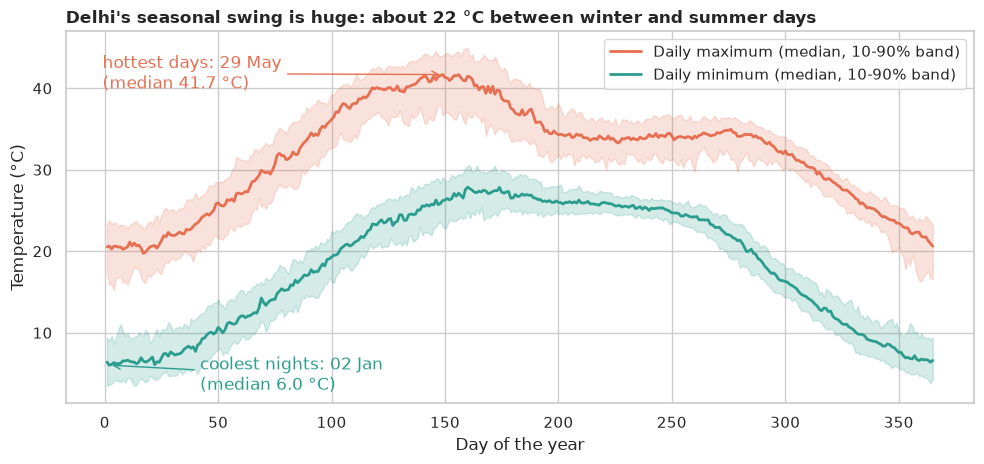

In [3]:
observed_days = daily["tmax"].notna().groupby(daily.index.year).sum()
COMPLETE_YEARS = observed_days[observed_days >= 360].index  # at most 5 missing days
HISTORY = daily[daily.index.year.isin(COMPLETE_YEARS)]
print(
    f"Complete years used for yearly analyses: {COMPLETE_YEARS.min()} to {COMPLETE_YEARS.max()} "
    f"({len(COMPLETE_YEARS)} years). Excluded: "
    f"{sorted(set(daily.index.year) - set(COMPLETE_YEARS))}"
)
by_day = HISTORY.groupby(np.minimum(HISTORY.index.dayofyear, 365))[["tmax", "tmin"]]
typical = by_day.median()
band = {q: by_day.quantile(q) for q in (0.1, 0.9)}

fig, ax = plt.subplots(figsize=(10, 4.8))
days = typical.index.to_numpy()
for column, color, label in (("tmax", ORANGE, "Daily maximum"), ("tmin", TEAL, "Daily minimum")):
    ax.fill_between(days, band[0.1][column], band[0.9][column], color=color, alpha=0.2)
    ax.plot(days, typical[column], color=color, lw=2, label=f"{label} (median, 10-90% band)")
hottest = int(typical["tmax"].idxmax())
coldest = int(typical["tmin"].idxmin())


def date_of(day_of_year: int) -> str:
    """Formats a day-of-year number as a calendar date such as ``26 May``."""
    return (pd.Timestamp("2023-01-01") + pd.Timedelta(days=day_of_year - 1)).strftime("%d %b")


ax.annotate(
    f"hottest days: {date_of(hottest)}\n(median {typical['tmax'].max():.1f} °C)",
    (hottest, typical["tmax"].max()),
    (hottest - 150, 40),
    color=ORANGE,
    arrowprops={"arrowstyle": "->", "color": ORANGE},
)
ax.annotate(
    f"coolest nights: {date_of(coldest)}\n(median {typical['tmin'].min():.1f} °C)",
    (coldest, typical["tmin"].min()),
    (coldest + 40, 3),
    color=TEAL,
    arrowprops={"arrowstyle": "->", "color": TEAL},
)
ax.set_xlabel("Day of the year")
ax.set_ylabel("Temperature (°C)")
ax.legend(loc="upper right")
ax.set_title(
    f"Delhi's seasonal swing is huge: about {typical['tmax'].max() - typical['tmax'].min():.0f} °C "
    "between winter and summer days",
    loc="left",
    fontweight="bold",
)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_seasonal_cycle.png", dpi=150)
plt.show()

**How to read this.** The solid lines are the median temperature for each day of the year (1951 to 2023) and the shaded bands cover the middle 80% of years. The seasonal swing is enormous: median daily highs go from about **20 °C in mid-January to about 42 °C around 29 May**, a 22-degree gap, with a flat shoulder of about 34 °C during the monsoon (July to September) when clouds and rain hold the heat down. The coldest nights are in January. By comparison, any year-to-year change is going to be tiny, which is why we compare **yearly averages**, where the season cancels out.

## 6. H1 to H3: is Delhi warming?

*What:* average each year's daily maximum and minimum, then test for a trend with Mann-Kendall and estimate its size with the Theil-Sen slope and a 95% CI. *How to read:* a slope of +0.1 °C per decade is 1 °C of warming per century.

In [4]:
def trend_test(years: np.ndarray, values: np.ndarray) -> dict[str, float]:
    """Mann-Kendall trend test plus the Theil-Sen slope with a 95% CI.

    Args:
        years: Year numbers.
        values: One value per year.

    Returns:
        Kendall's tau, the p-value, and the slope (with CI) in units per decade.
    """
    tau = stats.kendalltau(years, values)
    slope, _, low, high = stats.theilslopes(values, years, alpha=0.95)
    return {
        "tau": float(tau.statistic),
        "p": float(tau.pvalue),
        "slope_per_decade": float(slope * 10),
        "ci_low": float(low * 10),
        "ci_high": float(high * 10),
    }


yearly = HISTORY.groupby(HISTORY.index.year)[["tmax", "tmin"]].mean()
hot_days = (HISTORY["tmax"] >= HOT_DAY_C).groupby(HISTORY.index.year).sum()
years = yearly.index.to_numpy()

trends = pd.DataFrame(
    {
        "Mean daily maximum (°C)": trend_test(years, yearly["tmax"].to_numpy()),
        "Mean daily minimum (°C)": trend_test(years, yearly["tmin"].to_numpy()),
        f"Days at or above {HOT_DAY_C:.0f} °C": trend_test(years, hot_days.to_numpy()),
    }
).T
trends["p_holm"] = multipletests(trends["p"], method="holm")[1]
print(f"Years analysed: {years.min()} to {years.max()} ({len(years)} years)")
trends.style.format(
    {
        "tau": "{:+.2f}",
        "p": "{:.1e}",
        "slope_per_decade": "{:+.3f}",
        "ci_low": "{:+.3f}",
        "ci_high": "{:+.3f}",
        "p_holm": "{:.1e}",
    }
)

Years analysed: 1951 to 2022 (72 years)


,tau,p,slope_per_decade,ci_low,ci_high,p_holm
Mean daily maximum (°C),-0.13,9.6e-02,-0.051,-0.106,+0.012,1.3e-01
Mean daily minimum (°C),+0.30,2.4e-04,+0.098,+0.051,+0.156,7.1e-04
Days at or above 40 °C,-0.15,6.6e-02,-1.154,-2.353,+0.000,1.3e-01


**How to read this.** (`slope_per_decade` is in °C per decade for the first two rows, and in days per decade for the third.)

- **Daily maximum: fail to reject H₀.** τ ≈ −0.13, p ≈ 0.10 (Holm 0.13), and a Theil-Sen slope of about **−0.05 °C per decade** with a CI from roughly −0.11 to +0.01. The CI straddles 0: the average daytime high shows **no detectable trend** over 72 years (if anything it leans slightly down).
- **Daily minimum: reject H₀.** τ ≈ +0.30, Holm-adjusted p ≈ 7e-4, slope **+0.098 °C per decade** (95% CI about +0.05 to +0.16). **Nights are warming**, by roughly 0.7 °C over the 72 years.
- **Scorching days (≥ 40 °C): fail to reject.** τ ≈ −0.15, p ≈ 0.07 (Holm 0.13), slope about −1.2 days per decade with a CI that just touches 0. There is **no sign of *more* scorching days**, which surprises many people. (The count swings enormously from year to year: from 9 days in 1971 to 65 in 2010.)

Remember "fail to reject" is *not* "proved nothing is happening". It means this record can't see a trend in daytime highs.

### H2: are nights warming faster than days?

*What:* the minimum is rising while the maximum isn't, so the **daily temperature range (max minus min) is shrinking**. We test whether the two slopes differ by bootstrapping: re-draw years with replacement 2,000 times, recompute the Theil-Sen slope of (minimum − maximum) each time, and take the middle 95% of results. **H₀:** the difference in slopes is 0.

In [5]:
rng = np.random.default_rng(SEED)
gap_series = (yearly["tmin"] - yearly["tmax"]).to_numpy()
boot = []
for _ in range(N_BOOTSTRAP):
    pick = rng.integers(0, len(years), len(years))
    boot.append(stats.theilslopes(gap_series[pick], years[pick])[0] * 10)
low, high = np.percentile(boot, [2.5, 97.5])
observed = stats.theilslopes(gap_series, years)[0] * 10
print(
    f"Slope of (minimum - maximum): {observed:+.3f} °C per decade "
    f"(95% bootstrap CI {low:+.3f} to {high:+.3f})"
)
print(
    f"Mean daily range: {(yearly['tmax'] - yearly['tmin']).iloc[:10].mean():.2f} °C in the first "
    f"10 years vs {(yearly['tmax'] - yearly['tmin']).iloc[-10:].mean():.2f} °C in the last 10"
)

Slope of (minimum - maximum): +0.130 °C per decade (95% bootstrap CI +0.076 to +0.194)
Mean daily range: 13.55 °C in the first 10 years vs 13.04 °C in the last 10


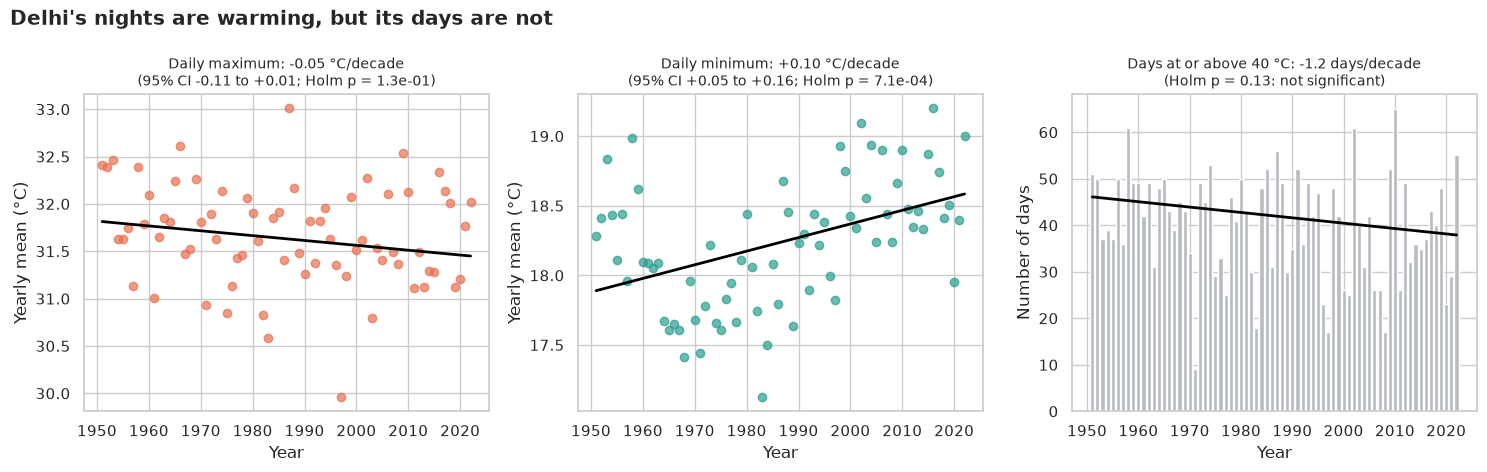

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, column, color, title in (
    (axes[0], "tmax", ORANGE, "Daily maximum"),
    (axes[1], "tmin", TEAL, "Daily minimum"),
):
    result = trends.loc[f"Mean daily {'maximum' if column == 'tmax' else 'minimum'} (°C)"]
    slope = stats.theilslopes(yearly[column], years)
    ax.plot(years, yearly[column], "o", color=color, alpha=0.7)
    ax.plot(years, slope[1] + slope[0] * years, color="black", lw=2)
    ax.set_title(
        f"{title}: {result['slope_per_decade']:+.2f} °C/decade\n"
        f"(95% CI {result['ci_low']:+.2f} to {result['ci_high']:+.2f}; "
        f"Holm p = {result['p_holm']:.1e})",
        fontsize=10,
    )
    ax.set_xlabel("Year")
    ax.set_ylabel("Yearly mean (°C)")

hot_result = trends.loc[f"Days at or above {HOT_DAY_C:.0f} °C"]
axes[2].bar(years, hot_days, color=GREY)
hot_slope = stats.theilslopes(hot_days.to_numpy(), years)
axes[2].plot(years, hot_slope[1] + hot_slope[0] * years, color="black", lw=2)
axes[2].set_title(
    f"Days at or above {HOT_DAY_C:.0f} °C: {hot_result['slope_per_decade']:+.1f} days/decade\n"
    f"(Holm p = {hot_result['p_holm']:.2f}: not significant)",
    fontsize=10,
)
axes[2].set_xlabel("Year")
axes[2].set_ylabel("Number of days")
fig.suptitle(
    "Delhi's nights are warming, but its days are not", x=0.01, ha="left", fontweight="bold"
)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_warming_trends.png", dpi=150)
plt.show()

**How to read this.** The black line in each panel is the Theil-Sen trend. **Left:** daytime highs wander between about 31 and 33 °C with no clear direction. **Middle:** the nightly lows drift upward, with the line rising about 0.7 °C over the record, mostly through a step up from the late 1970s. **Right:** the number of days at or above 40 °C varies a lot from year to year (from under 10 to 65) with no significant trend.

- **H2: reject H₀.** The slope of (minimum − maximum) is about **+0.13 °C per decade** (95% bootstrap CI roughly +0.08 to +0.19), so the CI excludes 0: **the gap between day and night temperatures is shrinking**. The average daily range (maximum minus minimum) was about 13.55 °C in the earliest ten years and is about 13.04 °C in the latest ten.

> **A caution before you read this as climate science.** The values in this file have many decimals (`20.13999939`) that look like they came from a *gridded or model-based product* rather than a single thermometer, and the file's description says part of the record comes from a different source. If the way the numbers were measured changed over the decades, that can create or hide trends. We can say what *this series* shows; we cannot say it reflects one station's thermometer without a break.

## 7. H4: stationarity, and a trap in the usual tests

Classic ARIMA-style models assume the series is **stationary**: its average and spread don't drift over time. Two standard tests check this, and they ask opposite questions:

- **ADF (Augmented Dickey-Fuller):** H₀ = the series has a **unit root** (it wanders like a random walk). A *small* p-value rejects that, so the series looks stationary.
- **KPSS:** H₀ = the series **is** stationary. A *large* p-value means we can't reject stationarity.

*What we'll do:* run both on the **raw** daily maximum, then again after removing the seasonal "road" (a linear trend plus 3 sine/cosine pairs fitted by least squares), leaving the **anomalies** (the ball's gap from the road).

In [7]:
def seasonal_design(index: pd.DatetimeIndex, origin: pd.Timestamp) -> np.ndarray:
    """Design matrix for the seasonal "road": intercept, linear trend and annual harmonics.

    Args:
        index: Dates to describe.
        origin: Date at which the trend variable is zero (fixed, so folds agree).

    Returns:
        Matrix with columns: 1, decades since origin, then sin/cos for each harmonic.
    """
    decades = (index - origin).days.to_numpy() / 3652.5
    angle = 2 * np.pi * index.dayofyear.to_numpy() / 365.25
    harmonics = [f(k * angle) for k in range(1, HARMONICS + 1) for f in (np.sin, np.cos)]
    return np.column_stack([np.ones(len(index)), decades, *harmonics])


def stationarity_tests(series: pd.Series) -> dict[str, float]:
    """Runs the ADF and KPSS stationarity tests.

    Args:
        series: A daily series (NaNs are dropped).

    Returns:
        ADF statistic and p-value, KPSS statistic and p-value (the KPSS p-value is
        capped at 0.10 and floored at 0.01 by the underlying lookup table).
    """
    values = series.dropna()
    adf = adfuller(values, autolag="AIC", result_object=False)
    with warnings.catch_warnings():
        # KPSS only tabulates p-values from 0.01 to 0.10 and warns when it is outside.
        warnings.simplefilter("ignore", InterpolationWarning)
        kp = kpss(values, regression="c", nlags="auto", result_object=False)
    return {"ADF statistic": adf[0], "ADF p": adf[1], "KPSS statistic": kp[0], "KPSS p": kp[1]}


tmax = daily["tmax"].interpolate(limit=3)
origin = tmax.index[0]
design = seasonal_design(tmax.index, origin)
observed = ~tmax.isna().to_numpy()
coef = np.linalg.lstsq(design[observed], tmax.to_numpy()[observed], rcond=None)[0]
road = pd.Series(design @ coef, index=tmax.index)
anomaly = tmax - road

tests_table = pd.DataFrame(
    {
        "Raw daily maximum": stationarity_tests(tmax),
        "Anomalies (season and trend removed)": stationarity_tests(anomaly),
    }
).T
share_explained = 1 - anomaly.var() / tmax.var()
print(
    f"The seasonal road explains {share_explained:.1%} of the day-to-day variation "
    "in maximum temperature"
)
print(f"Typical size of an anomaly (std): {anomaly.std():.2f} °C")
print(f"Fitted trend in the road: {coef[1]:+.3f} °C per decade")
tests_table.style.format(
    {"ADF statistic": "{:.1f}", "ADF p": "{:.1e}", "KPSS statistic": "{:.3f}", "KPSS p": "{:.2f}"}
)

The seasonal road explains 86.3% of the day-to-day variation in maximum temperature
Typical size of an anomaly (std): 2.49 °C
Fitted trend in the road: -0.039 °C per decade


,ADF statistic,ADF p,KPSS statistic,KPSS p
Raw daily maximum,-18.8,2.0e-30,0.009,0.10
Anomalies (season and trend removed),-33.6,0.0e+00,0.111,0.10


**How to read this.**

- **The seasonal road explains 86% of the day-to-day variation** in maximum temperature, and what's left (the anomaly) has a typical size of about **2.5 °C**.
- **The trap:** on the **raw** series, ADF gives p ≈ 2e-30 (a very strong rejection of a unit root) *and* KPSS gives p ≥ 0.10 (no evidence against stationarity). Both tests say **"stationary"**, yet the raw series swings by 20 °C every year! **ADF and KPSS look for random-walk drift and level shifts. They do *not* detect a repeating seasonal cycle.** A strongly seasonal series can pass both. Passing a stationarity test is therefore **not** permission to skip removing the season.
- After removing the road the series is still stationary (ADF p ≈ 0, KPSS p ≥ 0.10), and, importantly, it no longer carries a 20-degree cycle for a model to waste its effort on. The fitted trend of the road is about **−0.04 °C per decade**, matching the Theil-Sen result above.

### What does the leftover look like? ACF and PACF

*What:* the **autocorrelation function (ACF)** says how strongly today's anomaly resembles the anomaly *k* days ago; the **partial autocorrelation function (PACF)** says how much *extra* lag *k* adds once the closer days are accounted for. *How to read:* bars outside the grey band are significant. A slowly fading ACF with a PACF that drops after lag 1 is the classic signature of an **AR(1)**: "tomorrow remembers today".

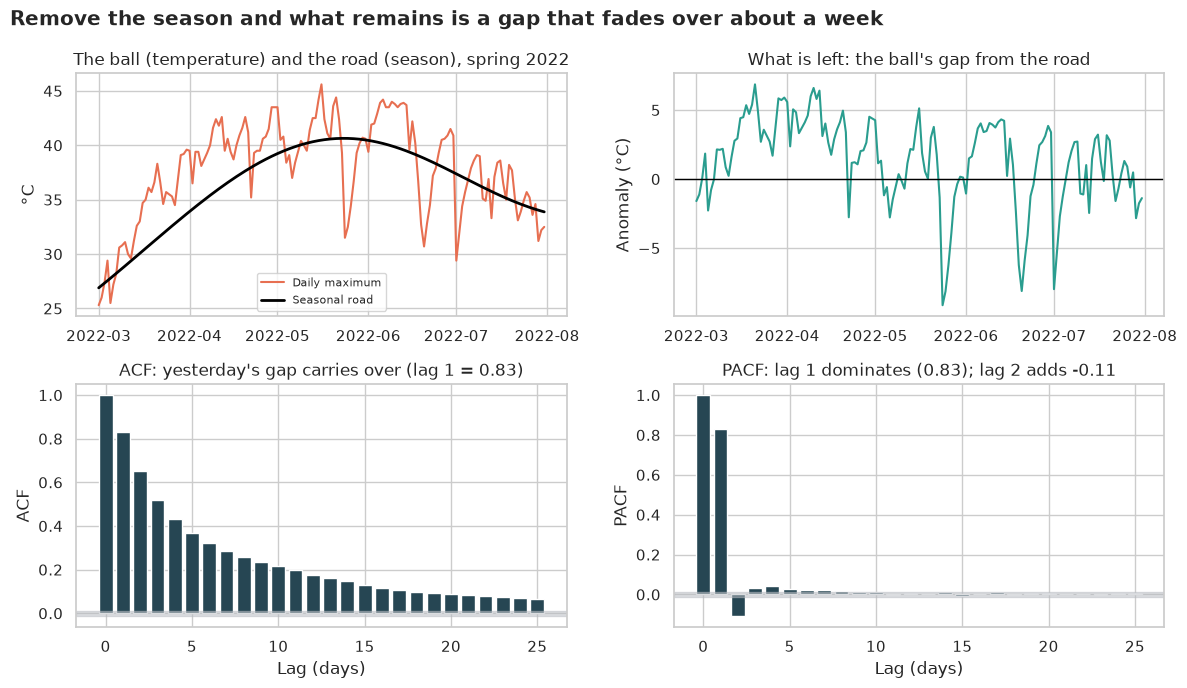

Autocorrelation of anomalies at lags 1, 2, 3, 5, 7, 14, 21: {1: np.float64(0.83), 2: np.float64(0.65), 3: np.float64(0.52), 5: np.float64(0.37), 7: np.float64(0.29), 14: np.float64(0.15), 21: np.float64(0.08)}


In [8]:
valid = anomaly.dropna()
n_lags = 25
acf_values = acf(valid, nlags=n_lags)
pacf_values = pacf(valid, nlags=n_lags)
band_limit = 1.96 / np.sqrt(len(valid))

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
recent = slice("2022-03-01", "2022-07-31")
axes[0, 0].plot(tmax[recent], color=ORANGE, label="Daily maximum")
axes[0, 0].plot(road[recent], color="black", lw=2, label="Seasonal road")
axes[0, 0].legend(loc="lower center", fontsize=8)
axes[0, 0].set_ylabel("°C")
axes[0, 0].set_title("The ball (temperature) and the road (season), spring 2022")
axes[0, 1].plot(anomaly[recent], color=TEAL)
axes[0, 1].axhline(0, color="black", lw=1)
axes[0, 1].set_ylabel("Anomaly (°C)")
axes[0, 1].set_title("What is left: the ball's gap from the road")
for ax, values, name in ((axes[1, 0], acf_values, "ACF"), (axes[1, 1], pacf_values, "PACF")):
    ax.bar(range(len(values)), values, color=NAVY)
    ax.axhspan(-band_limit, band_limit, color=GREY, alpha=0.5)
    ax.set_xlabel("Lag (days)")
    ax.set_ylabel(name)
axes[1, 0].set_title(f"ACF: yesterday's gap carries over (lag 1 = {acf_values[1]:.2f})")
axes[1, 1].set_title(
    f"PACF: lag 1 dominates ({pacf_values[1]:.2f}); lag 2 adds {pacf_values[2]:+.2f}"
)
fig.suptitle(
    "Remove the season and what remains is a gap that fades over about a week",
    x=0.01,
    ha="left",
    fontweight="bold",
)
fig.tight_layout()
fig.savefig(OUT_DIR / "03_stationarity_acf.png", dpi=150)
plt.show()
print(
    "Autocorrelation of anomalies at lags 1, 2, 3, 5, 7, 14, 21:",
    {k: round(acf_values[k], 2) for k in (1, 2, 3, 5, 7, 14, 21)},
)

**How to read this.** Top-left: the daily maximum (orange) wobbles around the seasonal road (black) during spring 2022. Top-right: subtract the road and you get the *anomalies* (teal), which wander above and below 0 for stretches of several days. Bottom: the ACF starts at **0.83 at lag 1** and decays slowly (0.65 at lag 2, 0.37 at lag 5, 0.29 at lag 7, 0.15 at lag 14, 0.08 at lag 21): a hot day tends to be followed by hot days, but the memory fades over **about one to two weeks**. The PACF is large at lag 1 (0.83), then small, which is the classic **AR(1)** fingerprint (a longer model can still help a bit, as we'll see).

## 8. H5 and H6: forecasting honestly

*What:* now the practical question: **how many days ahead does a model beat "a typical day for the date"?** We compare four forecasters:

1. **Climatology (the road):** predict the seasonal road for the target day. It ignores everything about the recent weather.
2. **Persistence:** predict that the temperature stays what it was at the forecast origin. The classic "tomorrow will be like today" baseline.
3. **Road + AR(p) anomaly:** predict the road plus a forecast of the anomaly, rolled forward one day at a time (this is an ARIMA(p, 0, 0) with the seasonal road removed first).
4. **AR(p) on the raw series (the legacy approach):** an ARIMA-style model fitted to the temperature with **no season removed**, so it can only fall back to the overall average at long horizons.

**How we avoid cheating (leakage).** For each test year from 2019 to 2023 we fit **everything** (the road, the AR order and coefficients) using **only the years before it**, and then forecast the whole test year from each possible forecast origin. The AR order is picked by AIC on the *training* years only. For each target day and each horizon (1 to 30 days) the forecast uses only data up to the origin, never the future.

**How we score.** **MAE (mean absolute error)**: the typical miss in °C; lower is better. **Skill** = 1 − MAE(model) / MAE(climatology): 0 means no better than the road, 1 means perfect, negative means worse. For the confidence intervals we **resample whole months** with replacement (a block bootstrap), because errors on neighbouring days are strongly correlated, and resampling single days would make the intervals far too narrow.

In [9]:
def fit_ar(series: np.ndarray, order: int) -> tuple[np.ndarray, float]:
    """Fits an AR(order) model by least squares, ignoring rows with missing values.

    Args:
        series: Values of the (anomaly) series.
        order: Number of lags.

    Returns:
        Coefficients (lag 1 first) and the AIC.
    """
    lags = np.column_stack([series[order - j - 1 : len(series) - j - 1] for j in range(order)])
    target = series[order:]
    rows = ~(np.isnan(lags).any(axis=1) | np.isnan(target))
    coefs = np.linalg.lstsq(lags[rows], target[rows], rcond=None)[0]
    rss = ((target[rows] - lags[rows] @ coefs) ** 2).sum()
    n = rows.sum()
    return coefs, float(n * np.log(rss / n) + 2 * order)


def best_ar(series: np.ndarray) -> tuple[np.ndarray, int]:
    """Chooses the AR order with the lowest AIC and returns its coefficients.

    Args:
        series: Training values of the (anomaly) series.

    Returns:
        Coefficients and the chosen order.
    """
    fits = {p: fit_ar(series, p) for p in range(1, MAX_AR_ORDER + 1)}
    order = min(fits, key=lambda p: fits[p][1])
    return fits[order][0], order


def ar_forecast(
    series: np.ndarray, coefs: np.ndarray, origins: np.ndarray, steps: int
) -> np.ndarray:
    """Rolls an AR model forward from each origin, one day at a time.

    Args:
        series: Anomaly values (observed history; only values up to each origin are used).
        coefs: AR coefficients, lag 1 first.
        origins: Integer positions of the forecast origins.
        steps: How many days ahead to forecast.

    Returns:
        Array of shape (len(origins), steps): column h-1 is the h-day-ahead forecast.
    """
    order = len(coefs)
    recent = np.column_stack([series[origins - j] for j in range(order)])  # newest first
    out = np.full((len(origins), steps), np.nan)
    for h in range(steps):
        nxt = recent @ coefs
        out[:, h] = nxt
        recent = np.column_stack([nxt, recent[:, :-1]])
    return out

In [10]:
MODELS = ["Climatology", "Persistence", "Road + AR anomaly", "AR on raw series (legacy)"]


def run_fold(series: pd.Series, test_year: int) -> dict:
    """Fits every model on years before ``test_year`` and forecasts the test year.

    Args:
        series: Daily maximum temperature on a complete daily calendar.
        test_year: Year to forecast; everything before it is training data.

    Returns:
        Dictionary with the fitted road, AR coefficients and orders, the origins used,
        and the forecast matrices (one column per horizon) for each model.
    """
    values = series.to_numpy()
    train = series.index < f"{test_year}-01-01"
    design = seasonal_design(series.index, series.index[0])
    fit_rows = train & ~np.isnan(values)
    road = design @ np.linalg.lstsq(design[fit_rows], values[fit_rows], rcond=None)[0]
    anomalies = values - road
    coefs, order = best_ar(anomalies[train])
    mean_level = np.nanmean(values[train])
    raw_centered = values - mean_level
    raw_coefs, raw_order = best_ar(raw_centered[train])

    first = int(np.argmax(series.index.year == test_year))
    last = int(np.where(series.index.year == test_year)[0][-1])
    origins = np.arange(first - max(HORIZONS), last)
    steps = max(HORIZONS)
    forecasts = {
        "Climatology": None,
        "Road + AR anomaly": ar_forecast(anomalies, coefs, origins, steps),
        "AR on raw series (legacy)": ar_forecast(raw_centered, raw_coefs, origins, steps),
    }
    return {
        "values": values,
        "road": road,
        "anomalies": anomalies,
        "mean_level": mean_level,
        "origins": origins,
        "forecasts": forecasts,
        "first": first,
        "last": last,
        "ar_order": order,
        "raw_order": raw_order,
        "coefs": coefs,
        "train": train,
    }


def fold_errors(series: pd.Series, fold: dict, test_year: int) -> pd.DataFrame:
    """Collects absolute forecast errors for every origin, horizon and model in a fold.

    Args:
        series: Daily maximum temperature on a complete daily calendar.
        fold: Output of :func:`run_fold`.
        test_year: Year being forecast.

    Returns:
        Long table indexed by target date with horizon and one absolute-error column per model.
    """
    values, road, origins = fold["values"], fold["road"], fold["origins"]
    rows = []
    for h in HORIZONS:
        valid = (origins + h >= fold["first"]) & (origins + h <= fold["last"])
        origin, target = origins[valid], origins[valid] + h
        actual = values[target]
        pos = np.searchsorted(origins, origin)
        predicted = {
            "Climatology": road[target],
            "Persistence": values[origin],
            "Road + AR anomaly": road[target] + fold["forecasts"]["Road + AR anomaly"][pos, h - 1],
            "AR on raw series (legacy)": fold["mean_level"]
            + fold["forecasts"]["AR on raw series (legacy)"][pos, h - 1],
        }
        frame = pd.DataFrame({"horizon": h, "year": test_year}, index=series.index[target])
        for name, forecast in predicted.items():
            frame[name] = np.abs(actual - forecast)
        rows.append(frame.dropna())
    return pd.concat(rows)


series = daily["tmax"].interpolate(limit=3)
folds = {year: run_fold(series, year) for year in TEST_YEARS}
errors = pd.concat([fold_errors(series, folds[year], year) for year in TEST_YEARS])
print(
    "AR order chosen by AIC on the training years:",
    {year: folds[year]["ar_order"] for year in TEST_YEARS},
)
print(
    f"Forecasts scored: {len(errors):,} (origin, horizon) pairs across {len(TEST_YEARS)} test years"
)
mae = errors.groupby("horizon")[MODELS].mean()
mae.round(2)

AR order chosen by AIC on the training years: {2019: 17, 2020: 17, 2021: 17, 2022: 17, 2023: 17}
Forecasts scored: 16,191 (origin, horizon) pairs across 5 test years


,Climatology,Persistence,Road + AR anomaly,AR on raw series (legacy)
horizon,,,,
1,2.3,1.39,1.32,1.37
2,2.3,1.96,1.75,1.87
3,2.3,2.27,1.93,2.12
5,2.3,2.67,2.09,2.40
7,2.3,2.78,2.14,2.53
10,2.3,2.99,2.20,2.74
14,2.3,3.33,2.24,3.01
21,2.3,3.83,2.27,3.36
30,2.3,4.48,2.29,3.88


**How to read this.** (Each row is a forecast horizon in days, each column a model, and the numbers are the average miss in °C; lower is better.)

- **Climatology has the same error at every horizon (2.30 °C)**, because it ignores the recent weather by design. It's the bar to beat.
- **Road + AR anomaly is the best model at every horizon**: a **1.3 °C** typical miss for tomorrow, rising to about **2.1 °C at 7 days** and climbing back to the climatology level (**2.3 °C**) by **3 to 4 weeks**. It *converges to* climatology and never does worse, because as the anomaly's memory fades, its forecast becomes the road.
- **Persistence ("tomorrow = today") is decent only for a day or two** (1.4 °C at 1 day) and then falls apart: by 3 days it is already **no better than climatology** (2.3 °C), and at 30 days it is nearly **twice as bad** (4.5 °C), because it keeps copying a temperature the season has moved away from.
- **The legacy approach (AR on the raw series)** is competitive at 1 day (1.4 °C), then it trails Road + AR at every horizon, and by 30 days it is far worse than climatology (3.9 vs 2.3 °C). Without the season removed, the model can only drift back to the *overall average temperature*, not to the *season's* temperature.

The AIC picks a long AR order, **17 lags** in every fold (shown above): most of the information is at lag 1, but the extra lags help a little.

In [11]:
def block_bootstrap_skill(
    model_err: pd.Series, reference_err: pd.Series, rng: np.random.Generator
) -> tuple[float, float, float]:
    """Bootstraps skill = 1 - MAE(model)/MAE(reference), resampling whole months.

    Args:
        model_err: Absolute errors of the model, indexed by target date.
        reference_err: Absolute errors of the reference model, same index.
        rng: Random generator.

    Returns:
        Skill, CI lower bound, CI upper bound.
    """
    months = model_err.index.to_period("M")
    sums = pd.DataFrame(
        {
            "m": model_err.groupby(months).sum(),
            "r": reference_err.groupby(months).sum(),
            "n": model_err.groupby(months).size(),
        }
    )
    picks = rng.integers(0, len(sums), (N_BOOTSTRAP, len(sums)))
    n = sums["n"].to_numpy()[picks].sum(axis=1)
    ratio = (sums["m"].to_numpy()[picks].sum(axis=1) / n) / (
        sums["r"].to_numpy()[picks].sum(axis=1) / n
    )
    lo, hi = np.percentile(1 - ratio, [2.5, 97.5])
    return float(1 - model_err.mean() / reference_err.mean()), float(lo), float(hi)


rng = np.random.default_rng(SEED)
skill_rows = []
for model in MODELS[1:]:
    for h in HORIZONS:
        subset = errors[errors["horizon"] == h]
        skill, lo, hi = block_bootstrap_skill(subset[model], subset["Climatology"], rng)
        skill_rows.append({"model": model, "horizon": h, "skill": skill, "lo": lo, "hi": hi})
skill = pd.DataFrame(skill_rows)
ar_skill = skill[skill["model"] == "Road + AR anomaly"].set_index("horizon")
beat = ar_skill[ar_skill["lo"] > 0]
useful = ar_skill[ar_skill["skill"] >= 0.05].index.max()
print(f"Road + AR beats climatology (95% CI excludes 0) out to {beat.index.max()} days ahead")
print(f"...but its skill is at least 5% only out to {useful} days ahead")
ar_skill[["skill", "lo", "hi"]].style.format("{:+.1%}")

Road + AR beats climatology (95% CI excludes 0) out to 21 days ahead
...but its skill is at least 5% only out to 7 days ahead


,skill,lo,hi
horizon,,,
1,+42.6%,+37.2%,+47.3%
2,+24.0%,+18.7%,+28.7%
3,+16.2%,+11.6%,+20.5%
5,+9.1%,+4.9%,+12.9%
7,+7.0%,+3.3%,+10.6%
10,+4.2%,+1.5%,+7.1%
14,+2.7%,+1.0%,+4.6%
21,+1.3%,+0.4%,+2.2%
30,+0.3%,-0.0%,+0.7%


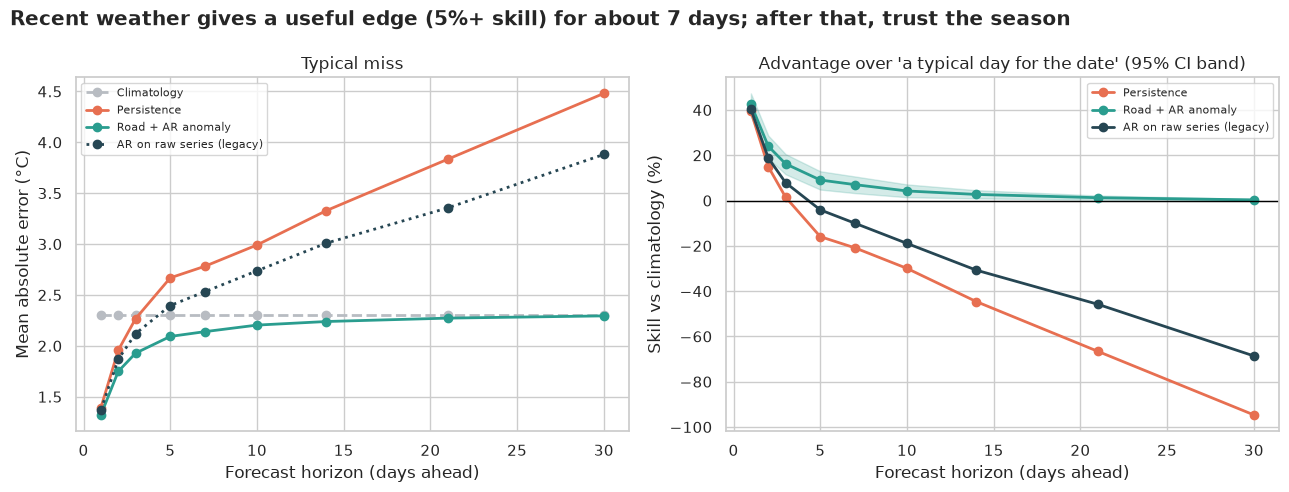

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
styles = {
    "Climatology": (GREY, "--"),
    "Persistence": (ORANGE, "-"),
    "Road + AR anomaly": (TEAL, "-"),
    "AR on raw series (legacy)": (NAVY, ":"),
}
for model, (color, style) in styles.items():
    axes[0].plot(mae.index, mae[model], style, color=color, lw=2, marker="o", label=model)
axes[0].set_xlabel("Forecast horizon (days ahead)")
axes[0].set_ylabel("Mean absolute error (°C)")
axes[0].legend(fontsize=8)
axes[0].set_title("Typical miss")

for model, color in (
    ("Persistence", ORANGE),
    ("Road + AR anomaly", TEAL),
    ("AR on raw series (legacy)", NAVY),
):
    part = skill[skill["model"] == model]
    axes[1].plot(part["horizon"], part["skill"] * 100, color=color, lw=2, marker="o", label=model)
    if model == "Road + AR anomaly":
        axes[1].fill_between(
            part["horizon"], part["lo"] * 100, part["hi"] * 100, color=color, alpha=0.2
        )
axes[1].axhline(0, color="black", lw=1)
axes[1].set_xlabel("Forecast horizon (days ahead)")
axes[1].set_ylabel("Skill vs climatology (%)")
axes[1].legend(fontsize=8)
axes[1].set_title("Advantage over 'a typical day for the date' (95% CI band)")
fig.suptitle(
    f"Recent weather gives a useful edge (5%+ skill) for about {useful} days; "
    "after that, trust the season",
    x=0.01,
    ha="left",
    fontweight="bold",
)
fig.tight_layout()
fig.savefig(OUT_DIR / "04_skill_by_horizon.png", dpi=150)
plt.show()

**How to read this.** Left: the climatology line (grey dashed) is flat at about 2.3 °C; the teal **Road + AR** line starts low and **rises to meet it**; the orange **persistence** line crosses above climatology after about 3 days and keeps climbing. Right: skill vs climatology. The teal line starts at about **+43%** (tomorrow's forecast has 43% less error than climatology), falls to about **+9% at 5 days**, **+7% at 7 days**, **+2.7% at 14 days** and **+1.3% at 21 days**, and is about **0 by 30 days** (+0.3%, CI touching 0). The shaded band is the 95% block-bootstrap CI. So the model's edge is statistically distinguishable from zero out to **21 days**, but it is only *practically* useful (at least 5% skill) out to about **7 days**: a gain of 1% in 3 weeks is real but trivial. Persistence's skill goes **negative after about 3 days**: copying today actively *hurts*.

This is the same story weather forecasters tell: skill from the current state fades within **one to two weeks**, after which only the season is predictable.

### H6: are our 95% forecast intervals honest?

*What:* a forecast is more useful with an uncertainty range. We build a 95% interval for the Road + AR forecast from the **errors the model made on the training years** (the 2.5th and 97.5th percentiles of signed errors at that horizon), then check how often the *held-out* actual temperature lands inside. **H₀:** coverage is 95%. If coverage is far from 95%, the intervals are lying about the model's confidence.

In [13]:
def interval_coverage(fold: dict, horizon: int) -> tuple[int, int, float]:
    """Checks a 95% forecast interval built from training errors against the test year.

    The interval is the 2.5th to 97.5th percentile of the signed errors the model made
    on the training years at this horizon, so no test information is used.

    Args:
        fold: Output of :func:`run_fold`.
        horizon: Forecast horizon in days.

    Returns:
        Number of test days inside the interval, number of test days scored, and the
        interval width in degrees C.
    """
    values, road, anomalies, coefs = fold["values"], fold["road"], fold["anomalies"], fold["coefs"]

    def errors_for(targets: np.ndarray) -> np.ndarray:
        forecast = ar_forecast(anomalies, coefs, targets - horizon, horizon)[:, horizon - 1]
        return values[targets] - (road[targets] + forecast)

    train_targets = np.arange(len(coefs) + horizon, fold["first"])
    low, high = np.nanpercentile(errors_for(train_targets), [2.5, 97.5])
    test_err = errors_for(np.arange(fold["first"], fold["last"] + 1))
    test_err = test_err[~np.isnan(test_err)]
    return int(((test_err >= low) & (test_err <= high)).sum()), len(test_err), float(high - low)


coverage_rows = []
for h in (1, 7, 14):
    results = [interval_coverage(folds[year], h) for year in TEST_YEARS]
    inside, total = sum(r[0] for r in results), sum(r[1] for r in results)
    coverage_rows.append(
        {
            "horizon": h,
            "coverage": inside / total,
            "n": total,
            "interval width (°C)": float(np.mean([r[2] for r in results])),
        }
    )
coverage = pd.DataFrame(coverage_rows).set_index("horizon")
coverage["z (vs 95%)"] = (coverage["coverage"] - 0.95) / np.sqrt(0.95 * 0.05 / coverage["n"])
coverage.style.format(
    {"coverage": "{:.1%}", "n": "{:.0f}", "interval width (°C)": "{:.1f}", "z (vs 95%)": "{:+.1f}"}
)

,coverage,n,interval width (°C),z (vs 95%)
horizon,,,,
1,88.3%,1799,5.6,-13.1
7,91.6%,1799,9.5,-6.6
14,90.4%,1799,9.8,-9.0


**How to read this.** The coverage column says what share of held-out days fell inside the 95% interval. A value near 95% means honest intervals; clearly below it means over-confident. **Our intervals are over-confident: only about 88% (1 day), 92% (7 days) and 90% (14 days) of held-out days land inside.** The `z` column puts that gap at 6 to 13 standard errors (neighbouring days are correlated, so the true uncertainty is larger than this naive z suggests, but a gap of 3 to 7 percentage points is too big to call noise). **We reject H₀: the intervals are narrower than they should be.** Two likely reasons: errors measured on the *training* years (which the model was fitted to) are smaller than genuine out-of-sample errors, and the spread of weather errors changes with the season, so one interval for the whole year is too narrow in the volatile months and too wide in the calm ones. A season-specific or recalibrated interval would be the next step. The interval does get **wider as the horizon grows**, from about ±2.8 °C at 1 day to about ±4.9 °C at one to two weeks, which is the honest cost of looking further ahead.

### Seeing it work

*What:* the 7-day-ahead forecast for spring 2022, set against what actually happened and against the seasonal road. *How to read:* the teal line should follow the black (actual) line more closely than the grey road does when the weather departs from normal.

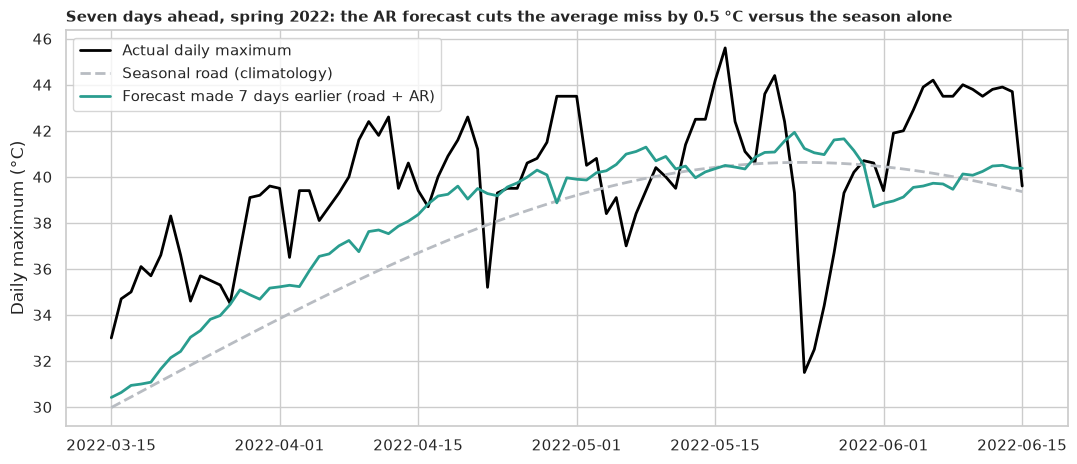

In [14]:
fold = folds[2022]
horizon = 7
window = pd.date_range("2022-03-15", "2022-06-15")
positions = series.index.get_indexer(window)
origins = positions - horizon
lookup = {int(o): i for i, o in enumerate(fold["origins"])}
forecast = np.array(
    [
        fold["road"][t] + fold["forecasts"]["Road + AR anomaly"][lookup[t - horizon], horizon - 1]
        for t in positions
    ]
)
actual = fold["values"][positions]
road_window = fold["road"][positions]
rmse_gain = np.nanmean(np.abs(actual - road_window)) - np.nanmean(np.abs(actual - forecast))

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(window, actual, color="black", lw=2, label="Actual daily maximum")
ax.plot(window, road_window, color=GREY, lw=2, ls="--", label="Seasonal road (climatology)")
ax.plot(window, forecast, color=TEAL, lw=2, label="Forecast made 7 days earlier (road + AR)")
ax.set_ylabel("Daily maximum (°C)")
ax.legend(loc="upper left")
ax.set_title(
    f"Seven days ahead, spring 2022: the AR forecast cuts the average miss by "
    f"{rmse_gain:.1f} °C versus the season alone",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "05_forecast_example.png", dpi=150)
plt.show()

**How to read this.** Black is what happened, grey is the typical-day road, teal is the forecast made a week earlier. In this window the actual temperatures sat several degrees **above the grey road for weeks** in March and April, and the teal forecast follows that warmth better than the road alone, because it **remembers** that recent days were warm (the forecast still lags a hot spell that keeps building). And where the weather turns suddenly, such as the sharp drop of about 9 °C around 22 to 23 May, nobody's seven-day-old forecast can see it coming. The average miss over this window falls by about 0.5 °C compared with the season alone.

## 9. 🎯 Takeaways

1. **The season dwarfs everything else.** Median highs swing from about 20 °C (mid-January) to 42 °C (around 29 May), and the seasonal road explains 86% of day-to-day variation.
2. **Nights are warming; days are not.** The daily minimum rises **+0.098 °C per decade** (95% CI +0.05 to +0.16, Holm p ≈ 7e-4), while the daily maximum shows no detectable trend (−0.05 °C/decade, CI −0.11 to +0.01). The day-night range is shrinking by about 0.13 °C per decade.
3. **No evidence of more scorching days.** Days at or above 40 °C show no significant trend (Holm p ≈ 0.13).
4. **Stationarity tests can pass on a strongly seasonal series.** ADF (p ≈ 2e-30) and KPSS both called the raw series stationary despite a 20 °C annual swing. Remove the season first, whatever the tests say.
5. **Recent weather helps for about two weeks, not more.** The best model (road + AR on the anomalies) cuts error by about 43% at 1 day, about 7% at 7 days, about 2.7% at 14 days and essentially nothing by 30 days. Persistence is worse than climatology after 3 days, and the legacy "ARIMA on the raw series" approach is worse than climatology at long horizons. The 95% intervals we built are over-confident (88% to 92% real coverage).

## 10. ⚠️ Limitations and edge cases

- **Unknown measurement homogeneity.** The decimals suggest a gridded or modelled product and the documentation mentions a change of source for recent years. Trends in a series stitched together from different sources can be artefacts, so these trend results describe *this file*, not a certified single-thermometer record.
- **Yearly means are not independent.** Neighbouring years are slightly correlated, which Mann-Kendall assumes away, so p-values for trends may be somewhat optimistic.
- **Only one city and one variable.** Daily maximum temperature in Delhi. Humidity, wind, rain and the heat index (the "feels like" temperature that matters for health) are not modelled.
- **Linear AR forecasts are limited.** They can't predict a sudden regime change (a monsoon onset, a western disturbance) and the Gaussian-style intervals ignore that extremes are fatter-tailed.
- **Five test years.** Rolling-origin evaluation covers 2019 to 2023 only; a different period could change the exact skill numbers.
- **Interval coverage check is rough.** Neighbouring days' errors are correlated, so the z-scores shown understate the real uncertainty about coverage, and the intervals themselves are over-confident (a known weakness we report rather than fix).
- **Gaps.** The file is empty from 2 December 2023 to 22 February 2024 (83 days). Shorter gaps were filled only up to 3 days, and 2023 and 2024 are excluded from the yearly trend tests (but 2023 is still used as a forecasting test year, scored only on days that exist).

---
*Run `uv run jupyter nbconvert --to html --execute ML/delhi-weather-arima/delhi_weather_arima.ipynb --output-dir docs --output ml-delhi-weather-arima` to rebuild the web version (`docs/ml-delhi-weather-arima.html`).*